In [6]:
import pandas as pd

FUEL = -0.056
DEG = 0.030

laps = pd.read_csv("../data/processed/laps_2026.csv")
race = laps[laps["session_name"] == "Race"].copy()

In [7]:
race["corrected"] = race["lap_duration"] - FUEL * race["lap_number"] - DEG * race["tyre_age"]

target = race.groupby(["location", "driver_number"]).agg(
    race_pace = ("corrected", "median"),
    race_laps = ("corrected", "size"),
).reset_index()

target = target[target["race_laps"] >= 10].copy()

In [8]:
target["session_best"] = target.groupby("location")["race_pace"].transform("min")
target["race_gap_pct"] = (target["race_pace"] / target["session_best"] - 1) * 100

print(len(target))

430


In [9]:
fp2 = pd.read_csv("../data/processed/fp2_pace_2026.csv")
data = fp2.merge(target, on = ["location", "driver_number"])
data.to_csv("../data/processed/dataset_2026.csv", index = False)

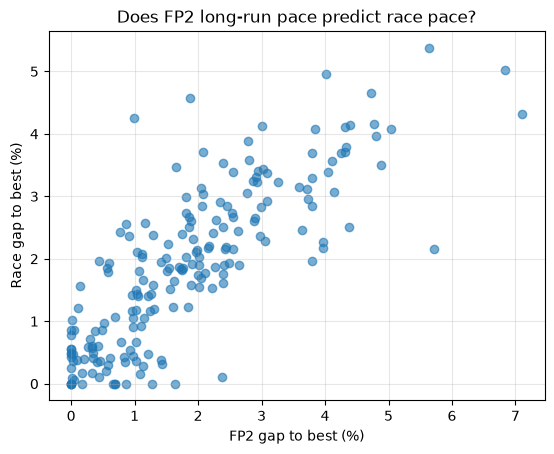

In [10]:
import matplotlib.pyplot as plt
plt.scatter(data["fp2_gap_pct"], data["race_gap_pct"], alpha=0.6)
plt.xlabel("FP2 gap to best (%)"); plt.ylabel("Race gap to best (%)")
plt.title("Does FP2 long-run pace predict race pace?")
plt.grid(alpha=0.3); plt.show()